# Comparing Interpolation Methods for Reconstructing Intraday MNQ Futures Prices
**Lameck Nyakweba** | Mathematics 5670-08, Fall 2026 | Austin Peay State University

This notebook carries out the experiment described in my proposal:

1. Load and clean about 20 trading days of 1-minute MNQ closing prices (9:30 a.m. to 4:00 p.m. New York time).
2. Implement the four methods: linear, natural cubic spline, PCHIP (Hermite), and local Newton divided differences (my own code).
3. Verify the code on functions with known answers (sin x and the Runge function).
4. Run the hide-and-reconstruct experiment with nodes every 5, 15, and 30 minutes.
5. Report accuracy, overshoot, timing, daily consistency, and open-versus-midday results, and check each hypothesis.

**Before running:** download the data with `python download_mnq.py` in this folder. All tables and figures are also saved to `results/` for the report and slides.

## 0. Setup

In [ ]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, PchipInterpolator

TICK = 0.25                    # MNQ minimum price movement, in index points
SPACINGS = [5, 15, 30]         # minutes between kept prices (nodes)
NEWTON_DEGREES = [2, 3, 5]
OPEN_WINDOW = (0, 30)          # 9:30-10:00, as minutes after the open
MIDDAY_WINDOW = (120, 240)     # 11:30-13:30
MIN_BARS_PER_DAY = 370         # a full session has 390; shorter days are excluded
TIMING_REPEATS = 5

DATA_FILE = Path("data/mnq_1m_raw.csv")
RESULTS = Path("results")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Load and clean the data
The raw file holds every 1-minute bar Yahoo returned, with timestamps in UTC. I convert the timestamps to New York time, remove duplicates, keep only the closing price, and keep only the regular session (9:30 to 15:59 bar labels, which is 390 bars on a full day). Each bar gets a `minute` number counting from the open (0 = 9:30, 389 = 15:59).

In [ ]:
raw = pd.read_csv(DATA_FILE, index_col="Datetime")
raw.index = pd.to_datetime(raw.index, utc=True).tz_convert("America/New_York")
print(f"Raw file: {len(raw):,} bars from {raw.index.min()} to {raw.index.max()}")

prices = raw[~raw.index.duplicated(keep="first")].sort_index()[["Close"]].dropna()
session = prices.between_time("09:30", "15:59")
session = session[session.index.dayofweek < 5].copy()
session["minute"] = session.index.hour * 60 + session.index.minute - (9 * 60 + 30)
session["date"] = session.index.date

bars_per_day = session.groupby("date").size()
kept_days = bars_per_day[bars_per_day >= MIN_BARS_PER_DAY].index
excluded = bars_per_day[bars_per_day < MIN_BARS_PER_DAY]
data = session[session["date"].isin(kept_days)]

print(f"Duplicate timestamps removed: {raw.index.duplicated().sum()}")
print(f"Session days found: {len(bars_per_day)}  |  kept: {len(kept_days)}  |  excluded (short or holiday): {len(excluded)}")
print(f"Bars used: {len(data):,}  |  missing minutes on kept days: {390 * len(kept_days) - len(data)}")
if len(excluded):
    print("Excluded days (bars):", ", ".join(f"{d} ({n})" for d, n in excluded.items()))

Raw file: 28,295 bars from 2026-10-18 18:10:00-04:00 to 2026-11-16 10:53:00-05:00
Duplicate timestamps removed: 0
Session days found: 21  |  kept: 20  |  excluded (short or holiday): 1
Bars used: 7,791  |  missing minutes on kept days: 9
Excluded days (bars): 2026-11-16 (84)


**Why short days are excluded:** a shortened session (like the day after Thanksgiving) or a day with many missing bars would not be comparable with full days. Missing minutes on kept days are simply not used as test targets; I never fill in raw prices before the evaluation.

**Contract rolls:** Yahoo's `MNQ=F` is a continuous series that switches to the next contract near expiry, which can create a price jump between days. Because every day is interpolated on its own, a jump *between* days cannot affect the results. The table below shows the overnight change from each day's last session price to the next day's first, so any unusual jump is visible.

In [ ]:
daily = data.groupby("date")["Close"].agg(first="first", last="last", low="min", high="max", bars="size")
daily["overnight_change"] = daily["first"] - daily["last"].shift()
daily["day_range_ticks"] = (daily["high"] - daily["low"]) / TICK
daily

,first,last,low,high,bars,overnight_change,day_range_ticks
date,,,,,,,
2026-10-19,29778.25,29722.25,29668.75,29979.75,390,NaN,1244.0
2026-10-20,29572.50,29688.25,29405.75,29888.00,390,-149.75,1929.0
2026-10-21,29884.50,29997.50,29779.25,30110.50,390,196.25,1325.0
2026-10-22,29503.00,29147.00,29037.00,29576.75,390,-494.50,2159.0
2026-10-23,29052.50,29123.00,29008.75,29318.00,390,-94.50,1237.0
2026-10-26,29231.25,29439.75,29178.50,29564.75,390,108.25,1545.0
2026-10-27,29553.25,29813.25,29502.50,29877.25,390,113.50,1499.0
2026-10-28,29923.25,29992.00,29777.50,30004.75,390,110.00,909.0
2026-10-29,29576.50,29566.25,29420.00,29671.25,390,-415.50,1005.0


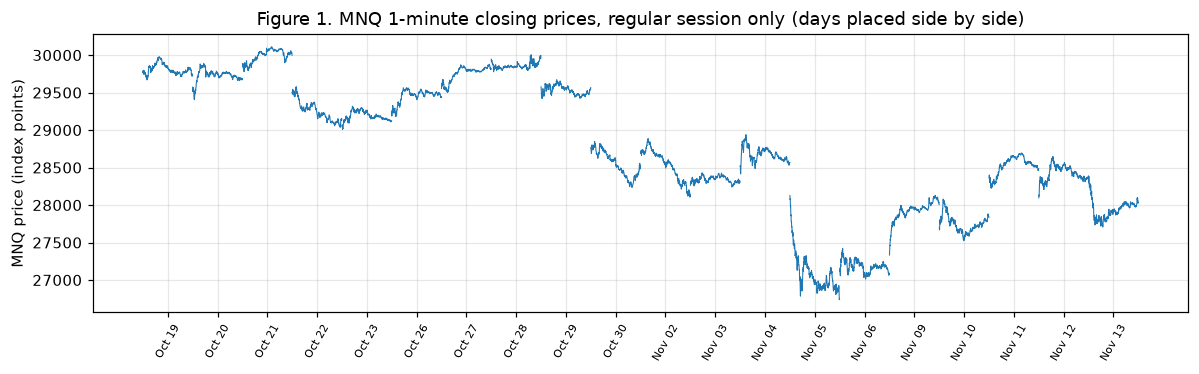

In [ ]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for i, (d, day) in enumerate(data.groupby("date")):
    ax.plot(i * 390 + day["minute"], day["Close"], lw=0.7, color="tab:blue")
ax.set_xticks([i * 390 + 195 for i in range(len(kept_days))])
ax.set_xticklabels([pd.Timestamp(d).strftime("%b %d") for d in kept_days], rotation=60, fontsize=7)
ax.set_ylabel("MNQ price (index points)")
ax.set_title("Figure 1. MNQ 1-minute closing prices, regular session only (days placed side by side)")
fig.tight_layout(); fig.savefig(FIGURES / "fig1_prices.png"); plt.show()

## 2. The four interpolation methods
Every method has the same signature: given node times `xn`, node prices `yn`, and target times `xt`, return estimates at `xt`.

* **Linear**: `numpy.interp`, straight lines between neighbouring nodes.
* **Natural cubic spline**: SciPy `CubicSpline` with `bc_type="natural"` (second derivative zero at the first and last node).
* **PCHIP**: SciPy `PchipInterpolator`, piecewise cubic Hermite with slopes estimated from the data (Fritsch-Carlson).
* **Local Newton**: my own code, explained below.

In [ ]:
def interp_linear(xn, yn, xt):
    return np.interp(xt, xn, yn)


def interp_spline(xn, yn, xt):
    return CubicSpline(xn, yn, bc_type="natural")(xt)


def interp_pchip(xn, yn, xt):
    return PchipInterpolator(xn, yn)(xt)

### Local Newton divided differences (my own implementation)
**Divided-difference table.** The coefficients of the Newton form are the top edge of the table
$f[x_0],\ f[x_0,x_1],\ \dots,\ f[x_0,\dots,x_n]$, where $f[x_i,\dots,x_{i+j}] = \dfrac{f[x_{i+1},\dots,x_{i+j}] - f[x_i,\dots,x_{i+j-1}]}{x_{i+j}-x_i}$.
The loop below builds the table one column at a time, overwriting the array in place.

**Evaluation.** $p(t) = c_0 + c_1(t-x_0) + c_2(t-x_0)(t-x_1) + \dots$ is evaluated in nested (Horner-like) form, from the last coefficient back to the first.

**Window.** For each hidden price, I use $n+1$ nodes: the two nodes on either side of the target, then the next nearest node on either side until the window is full (ties go to the earlier node). Near the start or end of the session the window shifts inward.

**Centering and scaling.** Inside each window, times are mapped to roughly $[-1, 1]$ so that powers like $(t - x_0)^5$ stay small and rounding error stays low. A polynomial interpolant does not change under this change of variable, so the estimates are the same, just computed more accurately.

In [ ]:
def divided_differences(x, y):
    """Newton coefficients f[x0], f[x0,x1], ..., f[x0,...,xn]."""
    coef = np.array(y, dtype=float)
    for j in range(1, len(x)):
        coef[j:] = (coef[j:] - coef[j - 1:-1]) / (x[j:] - x[:-j])
    return coef


def newton_eval(coef, x, t):
    """Evaluate the Newton form in nested (Horner-like) order."""
    result = coef[-1]
    for k in range(len(coef) - 2, -1, -1):
        result = result * (t - x[k]) + coef[k]
    return result


def newton_window(xn, i, size, t):
    """Indices lo..hi of `size` nodes: the bracketing pair xn[i], xn[i+1] plus the nearest others."""
    lo, hi = i, i + 1
    while hi - lo + 1 < size:
        can_left, can_right = lo > 0, hi < len(xn) - 1
        if can_left and (not can_right or t - xn[lo - 1] <= xn[hi + 1] - t):
            lo -= 1   # ties go to the earlier node
        else:
            hi += 1
    return lo, hi


def interp_newton(xn, yn, xt, degree):
    size = min(degree + 1, len(xn))
    brackets = np.clip(np.searchsorted(xn, xt, side="right") - 1, 0, len(xn) - 2)
    out = np.empty(len(xt))
    for k, (t, i) in enumerate(zip(xt, brackets)):
        lo, hi = newton_window(xn, i, size, t)
        xw, yw = xn[lo:hi + 1], yn[lo:hi + 1]
        center, scale = (xw[0] + xw[-1]) / 2, (xw[-1] - xw[0]) / 2
        u = (xw - center) / scale
        out[k] = newton_eval(divided_differences(u, yw), u, (t - center) / scale)
    return out


METHODS = {
    "Linear": interp_linear,
    "Natural spline": interp_spline,
    "PCHIP": interp_pchip,
    **{f"Newton deg {d}": (lambda xn, yn, xt, d=d: interp_newton(xn, yn, xt, d)) for d in NEWTON_DEGREES},
}
list(METHODS)

['Linear',
 'Natural spline',
 'PCHIP',
 'Newton deg 2',
 'Newton deg 3',
 'Newton deg 5']

## 3. Verifying the code on functions with known answers
Before using market data, I check that the code does what the theory says it should. If any of these checks failed, the MNQ results could not be trusted.

### 3.1 Every method passes exactly through the nodes

In [ ]:
xn = np.linspace(0, 2 * np.pi, 13)
yn = np.sin(xn)
for name, f in METHODS.items():
    print(f"{name:<15} max error at nodes: {np.max(np.abs(f(xn, yn, xn) - yn)):.2e}")

Linear          max error at nodes: 0.00e+00
Natural spline  max error at nodes: 5.54e-18
PCHIP           max error at nodes: 1.07e-17
Newton deg 2    max error at nodes: 2.29e-17
Newton deg 3    max error at nodes: 2.45e-16
Newton deg 5    max error at nodes: 2.22e-16


### 3.2 Newton of degree n reproduces polynomials of degree up to n exactly
I interpolate the cubic $p(x) = x^3 - 2x + 1$. Degrees 3 and 5 should be exact (error near $10^{-13}$); degree 2 cannot be, since a quadratic cannot match a cubic.

In [ ]:
cubic = lambda x: x**3 - 2 * x + 1
xn = np.linspace(-2, 2, 9); xt = np.linspace(-1.9, 1.9, 50)
for d in NEWTON_DEGREES:
    err = np.max(np.abs(interp_newton(xn, cubic(xn), xt, d) - cubic(xt)))
    print(f"Newton deg {d}: max error on the cubic = {err:.2e}")

Newton deg 2: max error on the cubic = 4.71e-02
Newton deg 3: max error on the cubic = 8.88e-16
Newton deg 5: max error on the cubic = 8.88e-16


### 3.3 Natural spline has zero second derivative at the end nodes; PCHIP never overshoots

In [ ]:
xn = np.linspace(0, 2 * np.pi, 13)
cs = CubicSpline(xn, np.sin(xn), bc_type="natural")
print(f"Spline second derivative at the ends: {cs(xn[0], 2):.1e}, {cs(xn[-1], 2):.1e}")

# A step-like, non-decreasing data set: does each method stay within the data range?
xs = np.arange(8.0); ys = np.array([0, 0, 0, 1, 1, 1, 1, 1], dtype=float)
fine = np.linspace(0, 7, 701)
for name in ["Linear", "Natural spline", "PCHIP"]:
    est = METHODS[name](xs, ys, fine)
    print(f"{name:<15} range [{est.min():+.3f}, {est.max():+.3f}]   non-decreasing: {bool(np.all(np.diff(est) >= -1e-12))}")

Spline second derivative at the ends: 1.3e-15, 4.4e-16
Linear          range [+0.000, +1.000]   non-decreasing: True
Natural spline  range [-0.109, +1.108]   non-decreasing: False
PCHIP           range [+0.000, +1.000]   non-decreasing: True


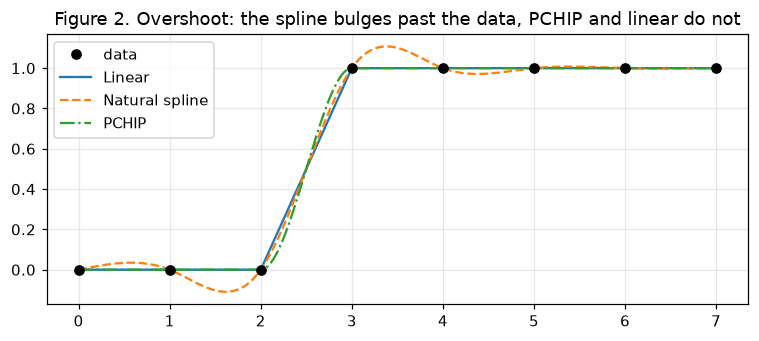

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(xs, ys, "ko", label="data", zorder=3)
for name, style in [("Linear", "-"), ("Natural spline", "--"), ("PCHIP", "-.")]:
    ax.plot(fine, METHODS[name](xs, ys, fine), style, label=name)
ax.set_title("Figure 2. Overshoot: the spline bulges past the data, PCHIP and linear do not")
ax.legend(); fig.tight_layout(); fig.savefig(FIGURES / "fig2_overshoot_demo.png"); plt.show()

### 3.4 Convergence rates on sin x
For a smooth function, the error formula $f(x) - p_n(x) = \dfrac{f^{(n+1)}(\xi)}{(n+1)!}\prod_{i=0}^{n}(x - x_i)$ predicts that linear error shrinks like $h^2$ and natural spline error like $h^4$ (sin has zero second derivative at $0$ and $2\pi$, so the natural end condition is exact here). On a log-log plot, the slope of each line estimates its rate.

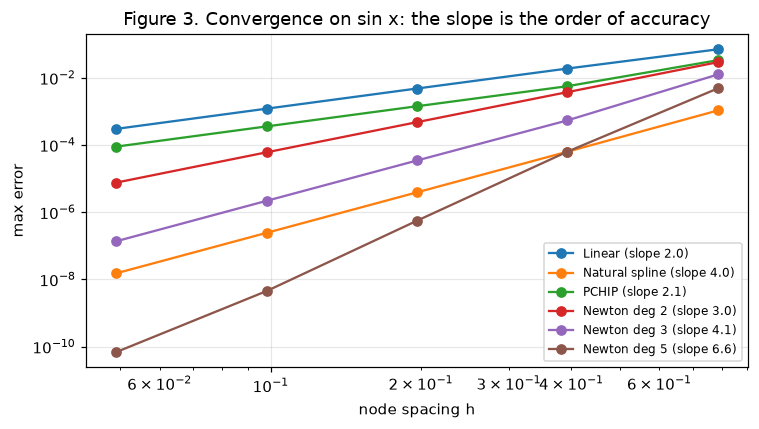

Linear            1.97
Natural spline    4.02
PCHIP             2.11
Newton deg 2      2.98
Newton deg 3      4.09
Newton deg 5      6.59
Name: estimated order (log-log slope), dtype: float64

In [ ]:
hs = 2 * np.pi / np.array([8, 16, 32, 64, 128])
fine = np.linspace(0, 2 * np.pi, 5001)
conv = {name: [] for name in METHODS}
for h in hs:
    xn = np.arange(0, 2 * np.pi + h / 2, h)
    for name, f in METHODS.items():
        conv[name].append(np.max(np.abs(f(xn, np.sin(xn), fine) - np.sin(fine))))

fig, ax = plt.subplots(figsize=(7, 4))
rates = {}
for name, errs in conv.items():
    rates[name] = np.polyfit(np.log(hs), np.log(errs), 1)[0]
    ax.loglog(hs, errs, "o-", label=f"{name} (slope {rates[name]:.1f})")
ax.set_xlabel("node spacing h"); ax.set_ylabel("max error")
ax.set_title("Figure 3. Convergence on sin x: the slope is the order of accuracy")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIGURES / "fig3_convergence_sin.png"); plt.show()
pd.Series(rates, name="estimated order (log-log slope)").round(2)

### 3.5 The Runge phenomenon: why Newton is used in local windows
A single polynomial through 15 equally spaced points of $1/(1+25x^2)$ swings wildly near the ends. Local Newton windows (degree 3) and the spline stay close to the true curve.

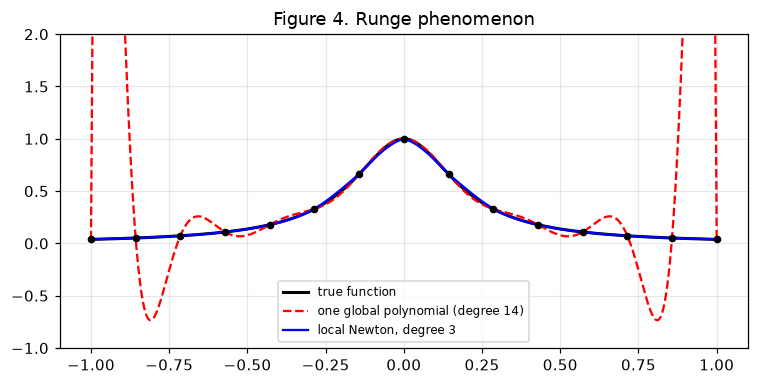

Max error, global degree-14 polynomial: 7.19
Max error, local Newton degree 3:       0.018


In [ ]:
runge = lambda x: 1 / (1 + 25 * x**2)
xn = np.linspace(-1, 1, 15); fine = np.linspace(-1, 1, 801)
global_poly = interp_newton(xn, runge(xn), fine, degree=len(xn) - 1)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(fine, runge(fine), "k", lw=2, label="true function")
ax.plot(fine, global_poly, "r--", label="one global polynomial (degree 14)")
ax.plot(fine, interp_newton(xn, runge(xn), fine, 3), "b-", label="local Newton, degree 3")
ax.plot(xn, runge(xn), "ko", ms=4)
ax.set_ylim(-1, 2); ax.legend(fontsize=8)
ax.set_title("Figure 4. Runge phenomenon")
fig.tight_layout(); fig.savefig(FIGURES / "fig4_runge.png"); plt.show()
print(f"Max error, global degree-14 polynomial: {np.max(np.abs(global_poly - runge(fine))):.2f}")
print(f"Max error, local Newton degree 3:       {np.max(np.abs(interp_newton(xn, runge(xn), fine, 3) - runge(fine))):.3f}")

## 4. The hide-and-reconstruct experiment
For each day and each spacing $h$:

* **Nodes** are the observed prices at minutes 0, $h$, $2h$, ... after the open, plus the first and last observed prices of the day (so nothing is ever extrapolated). If a scheduled node minute is missing in the data, that gap is simply wider.
* **Targets** are all other observed prices. Each method sees only the nodes and estimates the targets.
* For each target I store the true price, the estimate, and the two bracketing node prices (for the overshoot check). Each method is also timed: the median of 5 repeated runs.

In [ ]:
def run_day(day, h):
    m = day["minute"].to_numpy(dtype=float)
    y = day["Close"].to_numpy()
    is_node = (day["minute"].to_numpy() % h == 0)
    is_node[0] = is_node[-1] = True
    xn, yn, xt, yt = m[is_node], y[is_node], m[~is_node], y[~is_node]
    gap = np.searchsorted(xn, xt) - 1        # which pair of nodes brackets each target
    rows, timings = [], []
    for name, f in METHODS.items():
        runs = []
        for _ in range(TIMING_REPEATS):
            start = time.perf_counter()
            est = f(xn, yn, xt)
            runs.append(time.perf_counter() - start)
        timings.append({"h": h, "method": name, "seconds": np.median(runs)})
        rows.append(pd.DataFrame({
            "h": h, "method": name, "minute": xt, "true": yt, "est": est, "gap": gap,
            "left_node": yn[gap], "right_node": yn[gap + 1],
        }))
    return rows, timings


all_rows, all_timings = [], []
for d, day in data.groupby("date"):
    for h in SPACINGS:
        rows, timings = run_day(day, h)
        for r in rows:
            r["date"] = d
        for t in timings:
            t["date"] = d
        all_rows += rows; all_timings += timings

res = pd.concat(all_rows, ignore_index=True)
res["error"] = res["est"] - res["true"]
timing = pd.DataFrame(all_timings)
method_order = list(METHODS)
print(f"{len(res):,} reconstructed prices ({len(res) // len(METHODS):,} per method) across {res['date'].nunique()} days")
res.groupby(["h"])["minute"].count().div(len(METHODS)).rename("hidden prices per method")

125,862 reconstructed prices (20,977 per method) across 20 days


h
5     6213.0
15    7252.0
30    7512.0
Name: hidden prices per method, dtype: float64

## 5. Results
### 5.1 Overall accuracy, overshoot, and speed (Table 1)
* **MAE**: average size of a miss. **RMSE**: like MAE but punishes big misses more. **Max**: worst single miss. All in index points, and MAE/RMSE also in ticks (divide by 0.25).
* **Overshoot %**: share of gaps where at least one estimate falls outside the range of its two bracketing nodes (tolerance $10^{-9}$).
* **ms/day**: median time to build the interpolant and evaluate it for one day.

In [ ]:
tol = 1e-9
lo_b = np.minimum(res["left_node"], res["right_node"]) - tol
hi_b = np.maximum(res["left_node"], res["right_node"]) + tol
res["outside"] = (res["est"] < lo_b) | (res["est"] > hi_b)
gap_flags = res.groupby(["h", "method", "date", "gap"])["outside"].any()
overshoot = gap_flags.groupby(["h", "method"]).mean().mul(100)

g = res.groupby(["h", "method"])["error"]
table1 = pd.DataFrame({
    "MAE": g.apply(lambda e: e.abs().mean()),
    "RMSE": g.apply(lambda e: np.sqrt((e**2).mean())),
    "Max": g.apply(lambda e: e.abs().max()),
})
table1["MAE ticks"] = table1["MAE"] / TICK
table1["RMSE ticks"] = table1["RMSE"] / TICK
table1["Overshoot %"] = overshoot
table1["ms/day"] = timing.groupby(["h", "method"])["seconds"].median() * 1000
table1 = table1.reindex(pd.MultiIndex.from_product([SPACINGS, method_order], names=["h", "method"]))
table1.to_csv(RESULTS / "table1_overall.csv")
table1

MAE    RMSE      Max  MAE ticks  RMSE ticks  \
h  method                                                           
5  Linear          11.805  17.111  169.600     47.219      68.445   
   Natural spline  12.310  17.833  165.565     49.238      71.334   
   PCHIP           12.049  17.546  168.928     48.196      70.185   
   Newton deg 2    12.442  18.012  164.270     49.767      72.049   
   Newton deg 3    12.069  17.553  166.836     48.278      70.212   
   Newton deg 5    12.343  18.143  167.086     49.371      72.571   
15 Linear          18.971  27.368  192.633     75.882     109.472   
   Natural spline  19.402  27.818  192.550     77.608     111.271   
   PCHIP           19.212  27.737  200.798     76.849     110.948   
   Newton deg 2    19.585  28.119  197.939     78.338     112.476   
   Newton deg 3    19.295  27.851  208.362     77.181     111.405   
   Newton deg 5    20.279  29.791  246.072     81.117     119.165   
30 Linear          25.863  36.865  213.567    103.453     147.459   
   Natural spline  26.654  37.642  194.112    106.617     150.567   
   PCHIP           25.974  36.776  218.346    103.897     147.106   
   Newton deg 2    26.943  38.147  202.560    107.773     152.587   
   Newton deg 3    26.580  37.934  233.724    106.320     151.737   
   Newton deg 5    28.359  42.155  301.415    113.436     168.618   

                   Overshoot %  ms/day  
h  method                               
5  Linear                0.000   0.004  
   Natural spline       34.596   0.246  
   PCHIP                 0.000   0.283  
   Newton deg 2         36.136   4.194  
   Newton deg 3         21.245   5.263  
   Newton deg 5         29.332   7.919  
15 Linear                0.000   0.005  
   Natural spline       43.353   0.243  
   PCHIP                 0.000   0.283  
   Newton deg 2         44.316   4.762  
   Newton deg 3         28.709   6.203  
   Newton deg 5         38.150   9.176  
30 Linear                0.000   0.005  
   Natural spline       46.332   0.236  
   PCHIP                 0.000   0.295  
   Newton deg 2         44.402   4.886  
   Newton deg 3         30.116   6.597  
   Newton deg 5         45.560   9.622

### 5.2 Error versus spacing (H1)

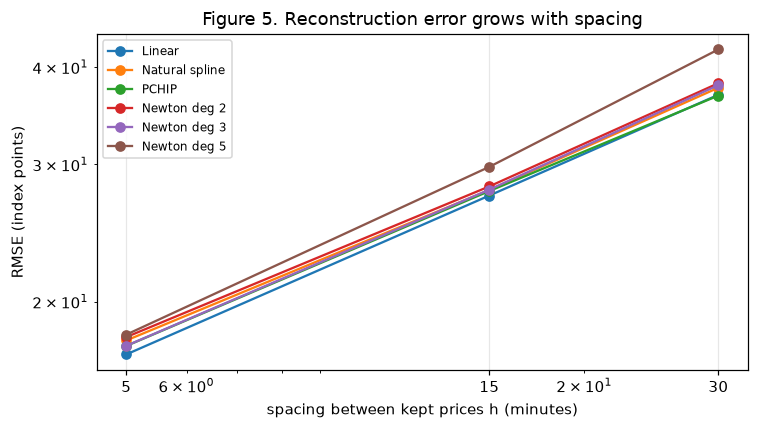

,slope on MNQ,slope on sin x (Section 3.4)
Linear,0.43,1.97
Natural spline,0.42,4.02
PCHIP,0.41,2.11
Newton deg 2,0.42,2.98
Newton deg 3,0.43,4.09
Newton deg 5,0.47,6.59


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
for name in method_order:
    ax.loglog(SPACINGS, table1.xs(name, level="method")["RMSE"], "o-", label=name)
ax.set_xticks(SPACINGS); ax.set_xticklabels(SPACINGS)
ax.set_xlabel("spacing between kept prices h (minutes)"); ax.set_ylabel("RMSE (index points)")
ax.set_title("Figure 5. Reconstruction error grows with spacing")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIGURES / "fig5_error_vs_spacing.png"); plt.show()

mkt_rates = {name: np.polyfit(np.log(SPACINGS), np.log(table1.xs(name, level="method")["RMSE"]), 1)[0] for name in method_order}
pd.DataFrame({"slope on MNQ": mkt_rates, "slope on sin x (Section 3.4)": rates}).round(2)

**How to read this:** on sin x, the slopes matched the theory (about 2 for linear, about 4 for the spline). On MNQ prices, if the slopes are much smaller and similar across methods, the smoothness assumption behind those rates does not hold for prices, so higher-order methods lose their theoretical advantage.

### 5.3 A close-up of one reconstruction

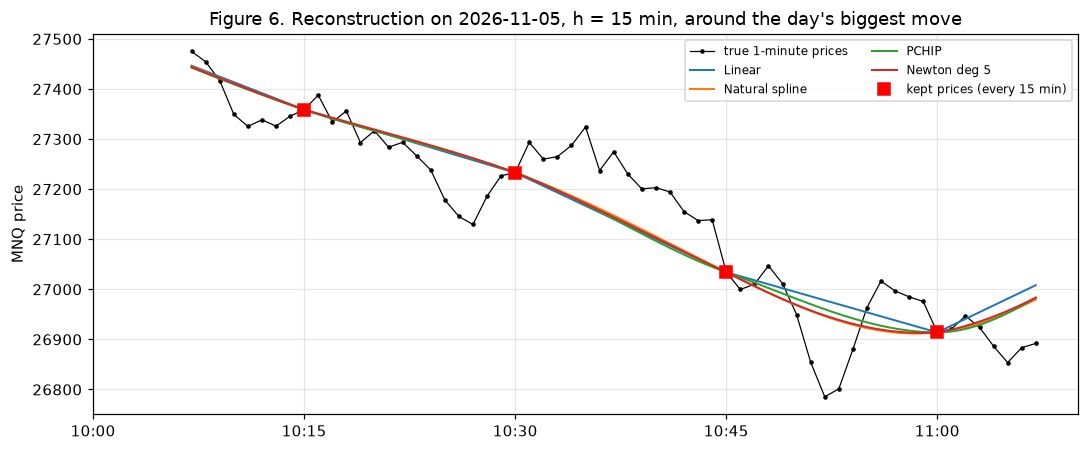

In [ ]:
h_show = 15
day_show = res.loc[res["h"] == h_show].groupby("date")["error"].apply(lambda e: e.abs().mean()).idxmax()
day = data[data["date"] == day_show]
# 60-minute window around the biggest 15-minute move of that day
move = day["Close"].diff(15).abs()
center = int(day["minute"].iloc[int(np.nanargmax(move.to_numpy()))])
a, b = max(center - 45, 0), min(center + 15, 389)
w = day[(day["minute"] >= a) & (day["minute"] <= b)]
nodes = day[(day["minute"] % h_show == 0) | (day["minute"].isin([day["minute"].iloc[0], day["minute"].iloc[-1]]))]
xn, yn = nodes["minute"].to_numpy(float), nodes["Close"].to_numpy()
fine = np.linspace(a, b, 600)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(w["minute"], w["Close"], "k.-", lw=0.8, ms=4, label="true 1-minute prices")
for name in ["Linear", "Natural spline", "PCHIP", "Newton deg 5"]:
    ax.plot(fine, METHODS[name](xn, yn, fine), label=name, lw=1.3)
sel = (xn >= a) & (xn <= b)
ax.plot(xn[sel], yn[sel], "s", color="red", ms=8, label=f"kept prices (every {h_show} min)", zorder=4)
ticks = np.arange(a - a % 15, b + 1, 15)
ax.set_xticks(ticks); ax.set_xticklabels([f"{(570 + int(t)) // 60}:{(570 + int(t)) % 60:02d}" for t in ticks])
ax.set_ylabel("MNQ price"); ax.legend(fontsize=8, ncol=2)
ax.set_title(f"Figure 6. Reconstruction on {day_show}, h = {h_show} min, around the day's biggest move")
fig.tight_layout(); fig.savefig(FIGURES / "fig6_example_reconstruction.png"); plt.show()

### 5.4 Day-to-day consistency (Table 2)
Daily RMSE for each method and spacing, summarized by its median and interquartile range (IQR) across days, plus the share of days on which each method beat linear interpolation.

In [ ]:
daily_rmse = res.groupby(["h", "method", "date"])["error"].apply(lambda e: np.sqrt((e**2).mean())).unstack("method")[method_order]
beats_linear = daily_rmse.lt(daily_rmse["Linear"], axis=0).groupby("h").mean().mul(100)
by_h = daily_rmse.groupby("h")
stats = {
    "median RMSE": by_h.median(),
    "IQR": by_h.quantile(0.75) - by_h.quantile(0.25),
    "% days beating linear": beats_linear,
}
table2 = pd.concat(stats, names=["statistic", "h"]).swaplevel()
table2 = table2.reindex(pd.MultiIndex.from_product([SPACINGS, list(stats)], names=["h", "statistic"]))
table2.to_csv(RESULTS / "table2_daily_consistency.csv")
table2

method                    Linear  Natural spline   PCHIP  Newton deg 2  \
h  statistic                                                             
5  median RMSE            14.558          14.874  14.676        14.962   
   IQR                     3.483           3.741   4.051         4.053   
   % days beating linear   0.000           5.000  15.000        10.000   
15 median RMSE            23.281          23.411  22.483        23.459   
   IQR                    12.521          11.333  11.742        11.790   
   % days beating linear   0.000          35.000  35.000        15.000   
30 median RMSE            36.171          35.596  34.239        35.133   
   IQR                    12.452          12.164  12.338        12.907   
   % days beating linear   0.000          45.000  60.000        25.000   

method                    Newton deg 3  Newton deg 5  
h  statistic                                          
5  median RMSE                  14.718        15.591  
   IQR                           3.579         3.925  
   % days beating linear        20.000        10.000  
15 median RMSE                  22.948        24.753  
   IQR                          11.001        12.338  
   % days beating linear        35.000        25.000  
30 median RMSE                  32.196        33.882  
   IQR                          13.286        17.710  
   % days beating linear        35.000        25.000

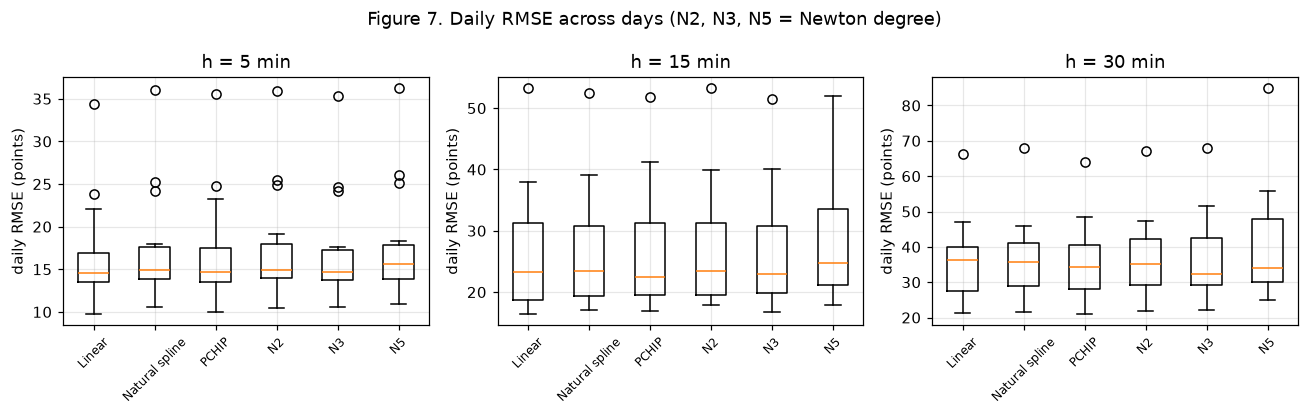

In [ ]:
fig, axes = plt.subplots(1, len(SPACINGS), figsize=(12, 3.8), sharey=False)
for ax, h in zip(axes, SPACINGS):
    d = daily_rmse.xs(h, level="h")
    ax.boxplot([d[m] for m in method_order], showfliers=True)
    ax.set_xticks(range(1, len(method_order) + 1)); ax.set_xticklabels([m.replace("Newton deg ", "N") for m in method_order], rotation=45, fontsize=8)
    ax.set_title(f"h = {h} min"); ax.set_ylabel("daily RMSE (points)")
fig.suptitle("Figure 7. Daily RMSE across days (N2, N3, N5 = Newton degree)")
fig.tight_layout(); fig.savefig(FIGURES / "fig7_daily_rmse.png"); plt.show()

### 5.5 Opening versus midday (Table 3)
I measure volatility directly as the standard deviation of 1-minute price changes in each window, then compare reconstruction RMSE in the same windows.

In [ ]:
def in_window(minutes, window):
    return (minutes >= window[0]) & (minutes < window[1])

vol = {}
for label, window in [("Open 9:30-10:00", OPEN_WINDOW), ("Midday 11:30-13:30", MIDDAY_WINDOW)]:
    in_win = data[in_window(data["minute"], window)]
    vol[label] = float(in_win.groupby("date")["Close"].diff().std())
print("Volatility (std of 1-minute price changes, points):", {k: round(v, 3) for k, v in vol.items()})

res["window"] = np.select([in_window(res["minute"], OPEN_WINDOW), in_window(res["minute"], MIDDAY_WINDOW)],
                          ["Open 9:30-10:00", "Midday 11:30-13:30"], default="other")
table3 = (res[res["window"] != "other"].groupby(["h", "window", "method"])["error"]
          .apply(lambda e: np.sqrt((e**2).mean())).unstack("method")[method_order])
table3.to_csv(RESULTS / "table3_open_vs_midday.csv")
table3

Volatility (std of 1-minute price changes, points): {'Open 9:30-10:00': 27.823, 'Midday 11:30-13:30': 13.133}


method                 Linear  Natural spline   PCHIP  Newton deg 2  \
h  window                                                             
5  Midday 11:30-13:30  13.504          14.062  13.706        14.316   
   Open 9:30-10:00     28.035          29.366  29.242        29.613   
15 Midday 11:30-13:30  21.042          21.930  21.396        22.119   
   Open 9:30-10:00     45.450          46.724  46.844        46.988   
30 Midday 11:30-13:30  28.279          29.503  28.602        29.958   
   Open 9:30-10:00     69.596          67.895  67.914        68.891   

method                 Newton deg 3  Newton deg 5  
h  window                                          
5  Midday 11:30-13:30        13.746        13.887  
   Open 9:30-10:00           29.931        32.965  
15 Midday 11:30-13:30        21.311        21.591  
   Open 9:30-10:00           48.260        58.854  
30 Midday 11:30-13:30        28.760        29.105  
   Open 9:30-10:00           71.788        84.277

### 5.6 Effect of Newton degree (H4)

In [ ]:
newton_names = [f"Newton deg {d}" for d in NEWTON_DEGREES]
table4 = table1.loc[(slice(None), newton_names), ["RMSE", "Max", "Overshoot %"]]
table4.to_csv(RESULTS / "table4_newton_degree.csv")
table4

,,RMSE,Max,Overshoot %
h,method,,,
5,Newton deg 2,18.012,164.270,36.136
15,Newton deg 2,28.119,197.939,44.316
30,Newton deg 2,38.147,202.560,44.402
5,Newton deg 3,17.553,166.836,21.245
15,Newton deg 3,27.851,208.362,28.709
30,Newton deg 3,37.934,233.724,30.116
5,Newton deg 5,18.143,167.086,29.332
15,Newton deg 5,29.791,246.072,38.150
30,Newton deg 5,42.155,301.415,45.560


## 6. What the results say about each hypothesis
This cell reads the tables above and states, in plain sentences, what the data show. Nothing here is typed by hand, so it always matches the current data.

In [ ]:
lines = []
rm = table1["RMSE"].unstack("method")

grows = {m: bool(np.all(np.diff(rm[m].to_numpy()) > 0)) for m in method_order}
lines.append(f"H1 (error grows with spacing): holds for {sum(grows.values())} of {len(grows)} methods"
             + ("" if all(grows.values()) else f"; exceptions: {[m for m, ok in grows.items() if not ok]}") + ".")

for h in SPACINGS:
    best = rm.loc[h].idxmin()
    lin = rm.loc[h, "Linear"]
    if best == "Linear":
        lines.append(f"   h = {h:>2} min: linear has the lowest RMSE ({lin:.3f} pts = {lin / TICK:.1f} ticks); no method beat the baseline.")
    else:
        diff = 100 * (rm.loc[h, best] - lin) / lin
        lines.append(f"   h = {h:>2} min: lowest RMSE is {best} ({rm.loc[h, best]:.3f} pts = {rm.loc[h, best] / TICK:.1f} ticks), "
                     f"{diff:+.1f}% versus linear ({lin:.3f} pts).")

for m in ["Natural spline", "PCHIP"]:
    shares = ", ".join(f"h={h}: {beats_linear.loc[h, m]:.0f}%" for h in SPACINGS)
    lines.append(f"H2 (no consistent gain over linear): {m} beat linear on {shares} of days.")

ov = table1["Overshoot %"].unstack("method")
lines.append(f"H3 (linear and PCHIP never overshoot): max overshoot rate linear = {ov['Linear'].max():.2f}%, "
             f"PCHIP = {ov['PCHIP'].max():.2f}% (spline up to {ov['Natural spline'].max():.1f}%). "
             + ("Check passed." if ov[["Linear", "PCHIP"]].to_numpy().max() == 0 else "CHECK FAILED: investigate the code."))

for h in SPACINGS:
    r = [rm.loc[h, n] for n in newton_names]
    trend = "rises" if np.all(np.diff(r) > 0) else "does not rise steadily"
    lines.append(f"H4 (higher Newton degree, more oscillation): at h = {h:>2}, RMSE for degrees {NEWTON_DEGREES} = "
                 f"{', '.join(f'{v:.3f}' for v in r)} ({trend}).")

o, mdy = vol["Open 9:30-10:00"], vol["Midday 11:30-13:30"]
lines.append(f"Sessions: 1-minute volatility was {o:.3f} pts at the open versus {mdy:.3f} at midday "
             f"({o / mdy:.1f}x). Linear RMSE at h=15: open {table3.loc[(15, 'Open 9:30-10:00'), 'Linear']:.3f}, "
             f"midday {table3.loc[(15, 'Midday 11:30-13:30'), 'Linear']:.3f}.")

summary = "\n".join(lines)
print(summary)
(RESULTS / "findings.txt").write_text(summary, encoding="utf-8")

H1 (error grows with spacing): holds for 6 of 6 methods.
   h =  5 min: linear has the lowest RMSE (17.111 pts = 68.4 ticks); no method beat the baseline.
   h = 15 min: linear has the lowest RMSE (27.368 pts = 109.5 ticks); no method beat the baseline.
   h = 30 min: lowest RMSE is PCHIP (36.776 pts = 147.1 ticks), -0.2% versus linear (36.865 pts).
H2 (no consistent gain over linear): Natural spline beat linear on h=5: 5%, h=15: 35%, h=30: 45% of days.
H2 (no consistent gain over linear): PCHIP beat linear on h=5: 15%, h=15: 35%, h=30: 60% of days.
H3 (linear and PCHIP never overshoot): max overshoot rate linear = 0.00%, PCHIP = 0.00% (spline up to 46.3%). Check passed.
H4 (higher Newton degree, more oscillation): at h =  5, RMSE for degrees [2, 3, 5] = 18.012, 17.553, 18.143 (does not rise steadily).
H4 (higher Newton degree, more oscillation): at h = 15, RMSE for degrees [2, 3, 5] = 28.119, 27.851, 29.791 (does not rise steadily).
H4 (higher Newton degree, more oscillation): at h = 

1219

## 7. Saved outputs
* `results/table1_overall.csv` to `table4_newton_degree.csv`: the tables above.
* `results/figures/fig1` to `fig7`: the figures, ready for the report and slides.
* `results/findings.txt`: the plain-sentence findings from Section 6.
* `data/download_log.json`: when and how the data were downloaded (dates, versions).